# Theoretical rBergomi hedge

In [1]:
import importlib
import sys
from pathlib import Path
import numpy as np

# Finding stuff
project_root = Path.cwd()
if not (project_root / "data" / "simulated").is_dir():
    project_root = project_root.parent
hedge_directory = project_root / "theoreticalhedge"
for directory in (project_root, hedge_directory):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

from data.simulated import simulated_data

importlib.reload(simulated_data)
from data.simulated.simulated_data import simulate_market

import parameters

importlib.reload(parameters)
from parameters import (
    S0, K, T, R, N, H, V0, nu, rho,
    n_outer, n_premium, n_inner_full,
    pricing_batch_size, inner_batch_size, path_batch_size,
    hurst_values, seeds,
)

market = simulate_market(
    S0=S0, T=T, N=N, H=H, V0=V0, nu=nu, rho=rho,
    T_fwd=R, n_paths=n_outer, rng=seeds["market"],
)
S, F = market["S"], market["F"]

market.update(
    payoff=np.maximum(S[:, -1] - K, 0.0),
    S0=S0, K=K, T=T, R=R, N=N,
    H=H, V0=V0, nu=nu, rho=rho,
)


In [2]:
from data.simulated.pricing import mc_pricer as pricing

importlib.reload(pricing)

premium_stats = pricing.pricer(
    M=n_premium, K=K, S_t=S0, T=T, N=N, H=H, V0=V0, nu=nu, rho=rho,
    batch_size=pricing_batch_size, rng=seeds["premium"], return_stats=True,
)
premium = premium_stats["price"]
premium_se = premium_stats["standard_error"]
print(f"Time-zero premium: {premium:.6f} (MC SE {premium_se:.6f})")
print(f"Approximate 95% interval: [{premium - 1.96*premium_se:.6f}, {premium + 1.96*premium_se:.6f}]")


Time-zero premium: 2.537465 (MC SE 0.103121)
Approximate 95% interval: [2.335347, 2.739582]


## Hedge


Let $\alpha=H-\tfrac12$ and $R=T_{\mathrm{fwd}}$. The normalized Gaussian perturbation is
$$r_t(s)=\frac{(s-t)^\alpha}{(R-t)^\alpha}.$$
We average the direction over every time bucket, giving a finite first bucket despite the singularity at $s=t$:
$$\bar r_j=\frac{(s_{j+1}-t)^{\alpha+1}-(s_j-t)^{\alpha+1}}{(\alpha+1)(s_{j+1}-s_j)(R-t)^\alpha}.$$

References: [Horvath et al., Equation (11) and Appendix C](../papers/DeepHedgingUnderRoughVol.pdf); [SigFormer, Appendix A](../papers/sigFormer.pdf).

For $P(x,\varepsilon)=\widehat u(t,x,\Theta_t+\varepsilon\bar r)$, the JAX derivatives give
$$\delta_t^S=\partial_xP(S_t,0),\qquad\delta_t^F=\frac{\partial_\varepsilon P(S_t,0)}{F_t}.$$

Compute both positions at every trading date on every market path. Holdings have shape `(n_outer, N, 2)`, with stock units first and forward-variance units second.


In [3]:
import hedge as hedging

importlib.reload(hedging)

full_hedge = hedging.full_holdings(
    market, n_inner=n_inner_full, seed=seeds["full_hedge"],
    path_batch_size=path_batch_size, inner_batch_size=inner_batch_size, progress=True,
)
holdings = full_hedge["JAX"]
print("JAX holdings shape:", holdings.shape)


Hedged date 1/30 (1,000 paths)
Hedged date 2/30 (1,000 paths)
Hedged date 3/30 (1,000 paths)
Hedged date 4/30 (1,000 paths)
Hedged date 5/30 (1,000 paths)
Hedged date 6/30 (1,000 paths)
Hedged date 7/30 (1,000 paths)
Hedged date 8/30 (1,000 paths)
Hedged date 9/30 (1,000 paths)
Hedged date 10/30 (1,000 paths)
Hedged date 11/30 (1,000 paths)
Hedged date 12/30 (1,000 paths)
Hedged date 13/30 (1,000 paths)
Hedged date 14/30 (1,000 paths)
Hedged date 15/30 (1,000 paths)
Hedged date 16/30 (1,000 paths)
Hedged date 17/30 (1,000 paths)
Hedged date 18/30 (1,000 paths)
Hedged date 19/30 (1,000 paths)
Hedged date 20/30 (1,000 paths)
Hedged date 21/30 (1,000 paths)
Hedged date 22/30 (1,000 paths)
Hedged date 23/30 (1,000 paths)
Hedged date 24/30 (1,000 paths)
Hedged date 25/30 (1,000 paths)
Hedged date 26/30 (1,000 paths)
Hedged date 27/30 (1,000 paths)
Hedged date 28/30 (1,000 paths)
Hedged date 29/30 (1,000 paths)
Hedged date 30/30 (1,000 paths)
JAX holdings shape: (1000, 30, 2)


## Self-financing portfolio and P&L

Start with the estimated premium $p_0$. After buying the initial positions, cash is
$$C_0=p_0-\delta_0^S S_0-\delta_0^F F_0.$$
Fund each rebalance from cash:
$$C_i=C_{i-1}-(\delta_i^S-\delta_{i-1}^S)S_i-(\delta_i^F-\delta_{i-1}^F)F_i.$$
At $T$, liquidate the hedge and pay the call payoff. This gives
$$\mathrm{P\&L}=p_0+\sum_{i=0}^{N-1}(\delta_i^S\Delta S_i+\delta_i^F\Delta F_i)-(S_T-K)^+.$$
Negative P&L is a loss. Borrowing and fractional positions are allowed. The forward is treated as a fully funded point-forward asset.

References: [Horvath et al., Section 2, Equation (1), and Section 3.3](../papers/DeepHedgingUnderRoughVol.pdf).

In [ ]:
import portfolio as accounting

importlib.reload(accounting)
prices = np.stack((S, F), axis=-1)
portfolio = accounting.self_financing_portfolio(
    prices, holdings, premium, market["payoff"]
)
pnl = portfolio["pnl"]

cash = portfolio["cash"]
np.testing.assert_allclose(
    cash[:, 1:-1], cash[:, :-2] - np.sum(
        np.diff(holdings, axis=1) * prices[:, 1:-1], axis=2
    ), rtol=1e-11, atol=1e-10,
)
np.testing.assert_allclose(
    cash[:, -1], cash[:, -2] + portfolio["liquidation"],
    rtol=1e-11, atol=1e-10,
)


## P&L summary

In [5]:
summary = accounting.pnl_summary(pnl, premium_standard_error=premium_se)
print(f"Mean P&L: {summary['mean']:.6f}")
print(f"Mean SE including premium MC error: {summary['mean_se_with_premium']:.6f}")
print("Mean 95% interval including premium MC error:", summary["mean_ci95_with_premium"])
print(f"P&L standard deviation: {summary['std']:.6f}")
print(f"MSE: {summary['mse']:.6f} (SE conditional on premium: {summary['mse_se']:.6f})")
print(f"RMSE: {summary['rmse']:.6f}")
print("P&L 1% / 5% quantiles:", summary["q01"], summary["q05"])
print("Worst-5% mean P&L:", summary["lower_tail_mean_05"])


Mean P&L: 0.094016
Mean SE including premium MC error: 0.106031
Mean 95% interval including premium MC error: (-0.11380447762597566, 0.30183663434196767)
P&L standard deviation: 0.780096
MSE: 0.616780 (SE conditional on premium: 0.073297)
RMSE: 0.785353
P&L 1% / 5% quantiles: -2.728611706651649 -1.1878831484986467
Worst-5% mean P&L: -2.213026359761619


In [6]:
results_directory = hedge_directory / "results"
results_directory.mkdir(exist_ok=True)


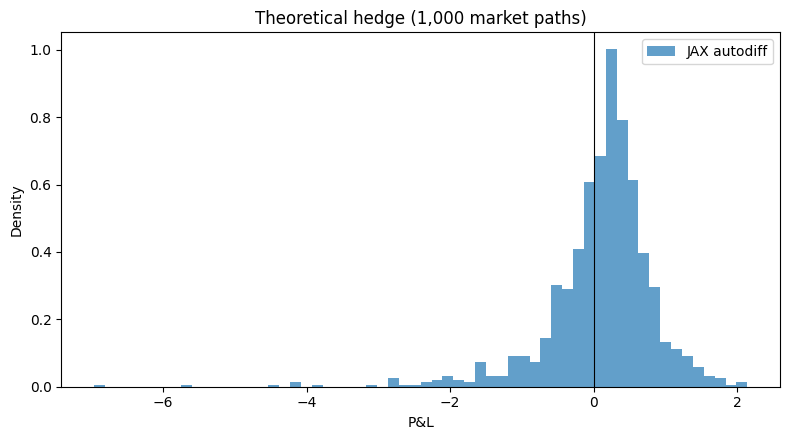

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(pnl, bins=60, density=True, alpha=0.7, label="JAX autodiff")
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set(xlabel="P&L", ylabel="Density",
       title=f"Theoretical hedge ({n_outer:,} market paths)")
ax.legend()
fig.tight_layout()
fig.savefig(results_directory / "pnl_distribution.png", dpi=180)
plt.show()


## Quadratic hedging loss by Hurst parameter



In [ ]:
from IPython.display import Markdown, display

hurst_rows = []

for hurst in hurst_values:
    hurst_market = simulate_market(
        S0=S0, T=T, N=N, H=hurst, V0=V0, nu=nu, rho=rho,
        T_fwd=R, n_paths=n_outer, rng=seeds["market"],
    )
    hurst_premium = pricing.pricer(
        M=n_premium, K=K, S_t=S0, T=T, N=N, H=hurst,
        V0=V0, nu=nu, rho=rho,
        batch_size=pricing_batch_size, rng=seeds["premium"],
        return_stats=True,
    )
    hurst_hedge = hedging.full_holdings(
        hurst_market, K=K, n_inner=n_inner_full,
        seed=seeds["full_hedge"], path_batch_size=path_batch_size,
        inner_batch_size=inner_batch_size,
    )
    hurst_prices = np.stack((hurst_market["S"], hurst_market["F"]), axis=-1)
    hurst_payoff = np.maximum(hurst_market["S"][:, -1] - K, 0.0)
    hurst_portfolio = accounting.self_financing_portfolio(
        hurst_prices, hurst_hedge["JAX"], hurst_premium["price"], hurst_payoff,
    )
    hurst_summary = accounting.pnl_summary(
        hurst_portfolio["pnl"], hurst_premium["standard_error"],
    )
    hurst_rows.append((hurst, hurst_summary["mse"]))

hurst_table = "| Hurst parameter | Model hedge quadratic loss |\n| --- | ---: |\n"
hurst_table += "\n".join(f"| {hurst:.1f} | {loss:.6f} |" for hurst, loss in hurst_rows)
display(Markdown(hurst_table))


| Hurst parameter | Model hedge quadratic loss |
| --- | ---: |
| 0.1 | 0.616780 |
| 0.2 | 0.276274 |
| 0.3 | 0.223724 |
| 0.4 | 0.206164 |